# M1-B2 — Classer les avis par motif d'insatisfaction

**Mode d'emploi.** Exécute les cellules dans l'ordre. Les `___` sont à compléter. Après chaque étape, le bloc
✅ indique le résultat que tu dois obtenir (à quelques centièmes près) : s'il est très différent, relis l'étape
avant d'avancer. Les cellules sans `___` sont fournies : lis-les, elles font partie de l'apprentissage.

In [31]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # avant tout « import keras » : Keras utilisera PyTorch

import json
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)
MODELS = ROOT / "models"

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

## Étape 1 — Démarrer

Cette cellule télécharge le modèle d'embeddings au premier lancement (environ 470 Mo, quelques minutes) :
lance-la tout de suite, et continue à lire pendant ce temps.

In [32]:
#It maps sentences & paragraphs to a 384 dimensional dense vector space and can be used for tasks like clustering or semantic search.
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(MODEL_NAME)
encoder.encode(["Le lit était très inconfortable.", "Le matelas était défoncé."]).shape

(2, 384)

✅ `(2, 384)` : deux phrases, 384 nombres chacune.

In [33]:
# nmr : embeddings and similarity calculation for the given sentences
embedings = encoder.encode(["Le lit était très inconfortable.", "Le matelas était défoncé."])
print(embedings)
print("--------------------------\n")
similarities = encoder.similarity(embedings, embedings)
print(similarities.shape)

[[ 7.00614899e-02 -7.50993639e-02 -1.11025706e-01  4.28151041e-01
   4.18772072e-01  1.34459555e-01 -9.18732956e-02  1.28750801e-01
   2.04140827e-01  1.40361711e-01 -1.73149765e-01  3.63200903e-01
   3.42908174e-01  6.97743446e-02 -6.66006375e-03 -1.89588040e-01
  -1.41160324e-01 -5.28003395e-01 -8.29127654e-02  5.95887780e-01
   2.74283700e-02  2.02082008e-01  5.47954679e-01 -4.95108426e-01
  -2.20117018e-01 -2.21729368e-01  4.26969945e-01 -1.70982778e-01
  -2.32854053e-01 -4.24582869e-01 -2.52149910e-01 -2.66319871e-01
  -5.69320917e-02  4.94851917e-03  1.98848531e-01 -2.21159622e-01
  -5.45828119e-02  4.07343566e-01 -5.92232719e-02 -2.02607363e-01
   1.55042022e-01  1.25261486e-01  1.47444140e-02 -1.84722364e-01
   5.09894788e-01  1.69401944e-01  9.31475461e-02 -3.19055349e-01
   4.41051871e-01  8.18377584e-02  8.62842277e-02  1.33056372e-01
  -8.52901638e-02 -3.99914056e-01 -5.35266757e-01 -1.12133697e-01
   1.28839135e-01 -3.36254165e-02 -3.16987306e-01  6.92090392e-01
  -3.12766

## Étape 2 — Explorer le corpus

- `avis_motifs.csv` : 1 200 avis de 2016, étiquetés par un LLM → pour **entraîner et tester**.
- `avis_recents.csv` : 180 avis de 2017, étiquetés à la main → **uniquement pour évaluer**, à la fin.

In [34]:
avis = pd.read_csv(DATA / "avis_motifs.csv")
recents = pd.read_csv(DATA / "avis_recents.csv")
print(len(avis), "avis,", len(recents), "avis récents")
avis["motif"].value_counts()

1200 avis, 180 avis récents


motif
proprete        189
bruit           184
equipements     144
chambre         139
restauration    138
accueil         138
reservation     112
prix             89
emplacement      67
Name: count, dtype: int64

✅ 9 motifs, de `proprete` (189 avis) à `emplacement` (67). Les classes sont **déséquilibrées** : c'est pourquoi on mesurera le F1 **macro** (chaque motif compte autant).

In [35]:
# *description du verbatim table 'avis' 2016, étiquetés par un LLM → pour **entraîner et tester**.
avis["texte"].str.len().describe().round()

count    1200.0
mean      170.0
std        64.0
min        28.0
25%       120.0
50%       167.0
75%       214.0
max       413.0
Name: texte, dtype: float64

In [36]:
#nmr

nombre = avis["motif"].value_counts(dropna=False)

pd.DataFrame({
    "nombre": nombre,
    "pourcentage": (nombre / len(avis) * 100).round(2)
})

,nombre,pourcentage
motif,,
proprete,189,15.75
bruit,184,15.33
equipements,144,12.00
chambre,139,11.58
restauration,138,11.50
accueil,138,11.50
reservation,112,9.33
prix,89,7.42
emplacement,67,5.58


In [37]:
# Echantillon
pd.set_option("display.max_colwidth", 200)
avis.sample(20, random_state=0)[["avis_id", "texte", "motif"]]

,avis_id,texte,motif
198,199,"Nous venons souvent, mais cette fois non. Impossible de dormir à cause du bruit de la rue.",bruit
328,329,Le veilleur de nuit dormait à la réception et ne répondait pas. On nous a répondu sèchement quand nous avons signalé un problème.,accueil
45,46,Les portes claquent dans le couloir toute la nuit. On entendait la tuyauterie à chaque fois qu'un voisin tirait la chasse. On attendait mieux.,bruit
263,264,"Vacances en famille, une semaine. Tout est payant : la serviette de piscine, le transat, le coffre.",prix
621,622,"Séjour professionnel de trois nuits. Les femmes de chambre parlaient fort dans le couloir dès 8 h. La climatisation faisait un bruit d'avion toute la nuit. Les murs sont en papier, on entend tout ...",bruit
520,521,"petit-dejeuner tres decevant : pain industriel et cafe tiede. soiree au bar de l'hotel jusqu'a 2 h, la musique resonnait dans la chambre. nous avions eu un bon tarif. dommage.",bruit
186,187,"Aucun commerce ni restaurant aux alentours. Chambre au-dessus de la discothèque, nuit blanche garantie. La fenêtre n'isole absolument pas du bruit du tramway. Dommage.",bruit
987,988,Franchement pas terrible. Le personnel semblait débordé et totalement indifférent. Nous avions eu un bon tarif.,restauration
1107,1108,"Nous venons souvent, mais cette fois non. Le parking est facturé 25 € la nuit en plus. Chambre sombre avec vue sur un mur. Pas de rideaux occultants, réveillés par le soleil à 6 h. Le mobilier est...",chambre
1052,1053,Nous avions choisi cet hôtel pour fêter notre anniversaire de mariage. Moisissures au plafond de la salle de bain. Le ménage n'a pas été fait pendant trois jours malgré nos demandes. J'espère que ...,proprete


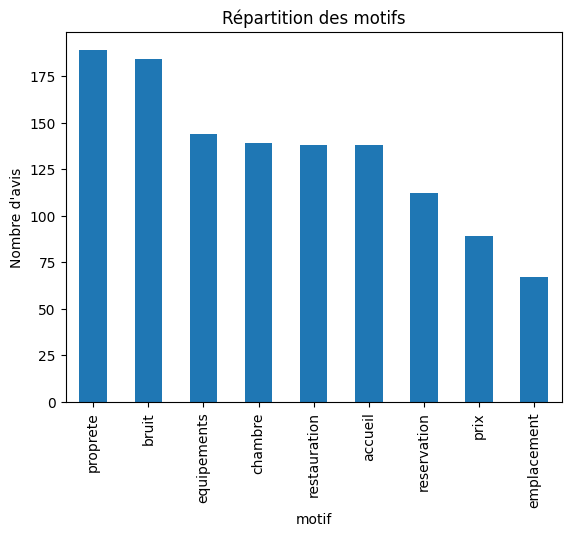

In [38]:
# !ncm
avis["motif"].value_counts().plot.bar()
plt.ylabel("Nombre d'avis")
plt.title("Répartition des motifs")
plt.show()

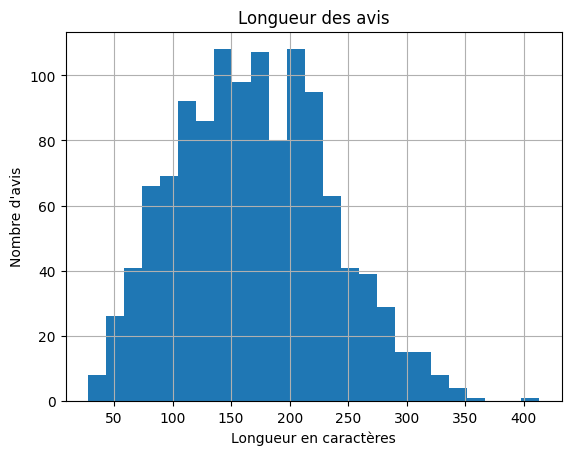

In [39]:
avis["texte"].str.len().hist(bins=25)
plt.xlabel("Longueur en caractères")
plt.ylabel("Nombre d'avis")
plt.title("Longueur des avis")
plt.show()

In [40]:
print("Historique :")
print(avis.isna().sum())
print("\nRécents :")
print(recents.isna().sum())


Historique :
avis_id      0
hotel        0
source       0
date_avis    0
note         0
texte        0
motif        0
dtype: int64

Récents :
avis_id      0
hotel        0
source       0
date_avis    0
texte        0
motif        0
dtype: int64


In [41]:
print("Textes dupliqués dans l'historique :", avis.duplicated("texte").sum())
print("Textes dupliqués dans les récents :", recents.duplicated("texte").sum())
print(
    "Textes identiques entre fichiers :",
    len(set(avis["texte"]) & set(recents["texte"])),
)

Textes dupliqués dans l'historique : 0
Textes dupliqués dans les récents : 0
Textes identiques entre fichiers : 0


### ✏️ Ton avis sur les étiquettes du LLM

Lis les 20 avis ci-dessus. Pour combien es-tu en désaccord avec l'étiquette ? Note ici 2 ou 3 `avis_id` douteux et pourquoi.

*…*

## Étape 3 — La référence : TF-IDF + régression logistique

On découpe en 75 % entraînement / 25 % test, **stratifié** (chaque motif garde sa proportion dans les deux jeux).

In [42]:
"""
Le test joue le rôle des futurs avis. Grâce à stratify, il garde les mêmes proportions de motifs que l'historique, et random_state=42 rend le découpage reproductible.

Jeu	Taille	Rôle
train	900 avis	Apprendre le vocabulaire TF-IDF et les poids du classifieur.
test	300 avis	Mesurer la performance sur des avis que le modèle n'a pas vus.
"""


train, test = train_test_split(avis, test_size=0.25, stratify=avis["motif"], random_state=42)

def f1_macro(y_true, y_pred):
    return round(f1_score(y_true, y_pred, average="macro"), 3)

tfidf = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000))
tfidf.fit(train["texte"], train["motif"])



/home/a895279/projects_CISIA/M1/Dev-IA-parcours-m1-b2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('logisticregression', LogisticRegression(max_iter=2000))])

In [43]:
print("*Entraînement* :", len(train), "avis")
display(train.head())

print("*Test* :", len(test), "avis")
display(test.head())

*Entraînement* : 900 avis


,avis_id,hotel,source,date_avis,note,texte,motif
265,266,Resort Hotel,Questionnaire,2016-07-15,1,"Séjour professionnel de trois nuits. Le couloir sentait le tabac froid. Les toilettes n'étaient pas nettoyées, c'était répugnant. Les draps n'avaient visiblement pas été changés. Des travaux ont c...",proprete
440,441,City Hotel,Booking,2016-10-31,2,Week-end en couple décevant. Accueil glacial à la réception. Le veilleur de nuit dormait à la réception et ne répondait pas. Le dîner au restaurant était fade et servi froid. Nous ne reviendrons pas.,accueil
987,988,City Hotel,Booking,2016-06-19,1,Franchement pas terrible. Le personnel semblait débordé et totalement indifférent. Nous avions eu un bon tarif.,restauration
878,879,City Hotel,Google,2016-06-30,1,"Avis honnête après 4 nuits : Le matelas était défoncé, j'ai encore mal au dos. Le canapé-lit des enfants était inconfortable au possible. Le chauffage ne marchait pas en plein mois de janvier. Trè...",chambre
202,203,City Hotel,Booking,2016-05-02,1,un employe a ete franchement impoli avec ma mere agee. nous ne reviendrons pas.,accueil


*Test* : 300 avis


,avis_id,hotel,source,date_avis,note,texte,motif
24,25,Resort Hotel,Google,2016-10-25,2,"Avis honnête après 4 nuits : La facture ne correspondait pas au prix de la réservation. Débités deux fois sur la carte bancaire, toujours pas remboursés.",reservation
422,423,City Hotel,TripAdvisor,2016-02-23,1,"L'emplacement est pourtant idéal. La salle de bain n'avait pas de porte, aucune intimité. À éviter.",restauration
546,547,City Hotel,Booking,2016-10-18,1,Une odeur d'égout dans la salle de bain toute la nuit. Dommage.,proprete
998,999,Resort Hotel,Booking,2016-06-18,2,la femme de chambre etait adorable. aucun choix pour les vegetariens. le diner au restaurant etait fade et servi froid. 2/5 et encore.,restauration
131,132,City Hotel,TripAdvisor,2016-10-30,1,"Nous venons souvent, mais cette fois non. Le restaurant mérite le détour. On entendait la tuyauterie à chaque fois qu'un voisin tirait la chasse.",bruit


In [44]:
# apres d'avoir tfidf.fit(train["texte"], train["motif"])
# on peut prédire sur le jeu de test
# et comparer avec les étiquettes réelles pour évaluer la performance
print(test["motif"])  # étiquettes réelles du jeu de test
#tfidf.predict(test["texte"])
predictions = tfidf.predict(test["texte"])  # prédictions sur le jeu de test
print(predictions)

24       reservation
422     restauration
546         proprete
998     restauration
131            bruit
            ...     
59             bruit
876            bruit
579         proprete
717         proprete
1040         chambre
Name: motif, Length: 300, dtype: object
['reservation' 'chambre' 'proprete' 'restauration' 'bruit' 'reservation'
 'chambre' 'accueil' 'prix' 'equipements' 'bruit' 'bruit' 'equipements'
 'bruit' 'equipements' 'emplacement' 'proprete' 'bruit' 'proprete'
 'accueil' 'prix' 'proprete' 'proprete' 'chambre' 'accueil' 'reservation'
 'bruit' 'proprete' 'proprete' 'equipements' 'prix' 'reservation'
 'proprete' 'equipements' 'proprete' 'proprete' 'restauration' 'bruit'
 'bruit' 'restauration' 'equipements' 'equipements' 'accueil'
 'reservation' 'accueil' 'proprete' 'chambre' 'emplacement' 'accueil'
 'bruit' 'chambre' 'restauration' 'proprete' 'prix' 'chambre' 'proprete'
 'accueil' 'accueil' 'bruit' 'restauration' 'bruit' 'emplacement'
 'accueil' 'prix' 'reservation' 'eq

In [45]:
print("TF-IDF — Fit transform train :", tfidf[:-1].fit_transform(train["texte"]))

TF-IDF — Fit transform train : <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 22193 stored elements and shape (900, 663)>
  Coords	Values
  (0, 578)	0.12359295137807676
  (0, 460)	0.1930040559711185
  (0, 145)	0.06721804225187519
  (0, 613)	0.15570596511879764
  (0, 394)	0.15357550767077002
  (0, 320)	0.1247865968620657
  (0, 138)	0.15203958958733668
  (0, 541)	0.19062767428239316
  (0, 580)	0.21626561706877845
  (0, 258)	0.18315623620266053
  (0, 321)	0.18295987527471175
  (0, 597)	0.20552641387194692
  (0, 656)	0.1767240428873612
  (0, 418)	0.16493760011522057
  (0, 384)	0.20883705662808205
  (0, 657)	0.09175326754917026
  (0, 525)	0.20883705662808205
  (0, 186)	0.21429386053429106
  (0, 52)	0.21429386053429106
  (0, 636)	0.21429386053429106
  (0, 659)	0.13934527411187192
  (0, 101)	0.21429386053429106
  (0, 160)	0.12251547756704019
  (0, 611)	0.19062767428239316
  (0, 398)	0.22048027456933747
  :	:
  (899, 145)	0.07111268627949893
  (899, 320)	0.06600839460101077
  (8

In [46]:
print("TF-IDF — Fit transform train :", tfidf[:-1].fit_transform(train["texte"], train["motif"]))

TF-IDF — Fit transform train : <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 22193 stored elements and shape (900, 663)>
  Coords	Values
  (0, 578)	0.12359295137807676
  (0, 460)	0.1930040559711185
  (0, 145)	0.06721804225187519
  (0, 613)	0.15570596511879764
  (0, 394)	0.15357550767077002
  (0, 320)	0.1247865968620657
  (0, 138)	0.15203958958733668
  (0, 541)	0.19062767428239316
  (0, 580)	0.21626561706877845
  (0, 258)	0.18315623620266053
  (0, 321)	0.18295987527471175
  (0, 597)	0.20552641387194692
  (0, 656)	0.1767240428873612
  (0, 418)	0.16493760011522057
  (0, 384)	0.20883705662808205
  (0, 657)	0.09175326754917026
  (0, 525)	0.20883705662808205
  (0, 186)	0.21429386053429106
  (0, 52)	0.21429386053429106
  (0, 636)	0.21429386053429106
  (0, 659)	0.13934527411187192
  (0, 101)	0.21429386053429106
  (0, 160)	0.12251547756704019
  (0, 611)	0.19062767428239316
  (0, 398)	0.22048027456933747
  :	:
  (899, 145)	0.07111268627949893
  (899, 320)	0.06600839460101077
  (8

In [47]:
print("TF-IDF — Transform test :", tfidf[:-1].transform(test["texte"]))

TF-IDF — Transform test : <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7392 stored elements and shape (300, 663)>
  Coords	Values
  (0, 33)	0.1825978626601161
  (0, 46)	0.12479222807919678
  (0, 57)	0.22130172831495776
  (0, 62)	0.28901218492205377
  (0, 89)	0.2296075184316591
  (0, 135)	0.2822458765878787
  (0, 145)	0.08334878938535516
  (0, 164)	0.19584080672075543
  (0, 190)	0.28901218492205377
  (0, 232)	0.27339034808310453
  (0, 252)	0.19173568766987195
  (0, 280)	0.22710941950178623
  (0, 318)	0.23565222439563283
  (0, 382)	0.12928759949749644
  (0, 394)	0.19043001275811353
  (0, 418)	0.20451873980822372
  (0, 458)	0.18548526549935873
  (0, 501)	0.28901218492205377
  (0, 526)	0.21602763954495988
  (0, 574)	0.1574576813414431
  (0, 599)	0.23357096731663046
  (1, 48)	0.22071825074429927
  (1, 53)	0.3297035225003317
  (1, 61)	0.24281982622795326
  (1, 145)	0.19899395573133544
  :	:
  (298, 561)	0.1727195531224189
  (298, 566)	0.13473134481428362
  (298, 567)	0.16242

In [48]:
print("TF-IDF — Feature names out :", tfidf[:-1].get_feature_names_out())

TF-IDF — Feature names out : ['10' '15' '17' '18' '25' '30' '40' '5e' 'abime' 'absent' 'absolument'
 'abîmé' 'accueil' 'accès' 'adorable' 'adultes' 'aeration' 'agee'
 'agréable' 'ai' 'aide' 'aimable' 'ajoutés' 'alentours' 'alimentaire'
 'alors' 'an' 'animations' 'anniversaire' 'annoncé' 'annoncée'
 'annulation' 'apres' 'après' 'arrivee' 'arrives' 'arrivé' 'arrivée'
 'arrivés' 'ascenseur' 'assez' 'attend' 'attendait' 'attendre' 'attendu'
 'attente' 'au' 'aucun' 'aucune' 'autour' 'autre' 'aux' 'avaient' 'avait'
 'avec' 'avion' 'avions' 'avis' 'avons' 'aération' 'baignaient' 'bain'
 'bancaire' 'bar' 'beaucoup' 'bien' 'blanche' 'bof' 'boissons' 'bon'
 'bord' 'bouchons' 'bouger' 'brouillés' 'bruit' 'buffet' 'bureau' 'bébé'
 'ca' 'cafards' 'cafe' 'café' 'calcaire' 'calme' 'camions' 'canape'
 'canapé' 'cantine' 'captait' 'carte' 'casse' 'cassé' 'catastrophique'
 'catégorie' 'cause' 'caution' 'ce' 'centre' 'cet' 'cette' 'chambre'
 'changés' 'chaque' 'chasse' 'chaud' 'chaude' 'chauffage' 'chaîn

In [49]:
""" 
On évalue sur le test parce qu'on veut savoir comment le modèle se comporte sur des avis qu'il n'a jamais vus
"""
print("TF-IDF — F1 macro test :", f1_macro(test["motif"], tfidf.predict(test["texte"])))

TF-IDF — F1 macro test : 0.911


✅ Environ **0,91**. C'est la référence à battre.

In [50]:
# vérifier
print("F1 macro entraînement :", f1_macro(train["motif"], tfidf.predict(train["texte"])))
print("-------------------"*30 + "\n")
print("F1 macro test         :", f1_macro(test["motif"], tfidf.predict(test["texte"])))

F1 macro entraînement : 0.911
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

F1 macro test         : 0.911


In [51]:
# voir les erreurs d' entrainement
erreurs_train = train.assign(prediction=tfidf.predict(train["texte"])).query("motif != prediction")
erreurs_train[["avis_id", "texte", "motif", "prediction"]].head(10)

print("Nombre d'erreurs d'entraînement :", len(erreurs_train))
print("-------------------"*30 + "\n")
display(erreurs_train[["avis_id", "texte", "motif", "prediction"]].head(10))

Nombre d'erreurs d'entraînement : 75
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------



,avis_id,texte,motif,prediction
987,988,Franchement pas terrible. Le personnel semblait débordé et totalement indifférent. Nous avions eu un bon tarif.,restauration,accueil
159,160,Bof. Traces de calcaire et de savon sur toute la paroi de douche. On attendait mieux.,restauration,proprete
602,603,Bof. Rapport qualité-prix catastrophique. Le wifi marchait bien. Les boissons au bar sont à des prix parisiens. Le lit grinçait au moindre mouvement. On attendait mieux.,chambre,prix
1100,1101,"Séjour gâché. Plus de croissants à 8 h 30, plus de tasses propres non plus. À ce tarif, on attend bien mieux. L'arrivée s'est faite rapidement.",prix,restauration
950,951,"Je ne recommande pas. Le parking est facturé 25 € la nuit en plus. Beaucoup trop cher pour ce que c'est. Chambre au-dessus de la discothèque, nuit blanche garantie. Dommage. 😡",bruit,prix
346,347,Avis honnête après 4 nuits : Pas d'option sans gluten malgré notre demande à la réservation. Le vin servi au verre était imbuvable. Le dîner au restaurant était fade et servi froid. La chasse d'ea...,equipements,restauration
1045,1046,Aucun commerce ni restaurant aux alentours. La direction devrait se pencher sérieusement sur la question.,equipements,emplacement
256,257,"Le restaurant mérite le détour. Le serveur a levé les yeux au ciel quand nous avons demandé une table. On s'est sentis de trop dès notre arrivée. Les murs sont en papier, on entend tout des voisin...",bruit,accueil
216,217,Bof. Lit beaucoup trop petit pour deux adultes. J'espère que ce commentaire fera bouger les choses.,bruit,chambre
769,770,"l'eau de la piscine etait trouble et pleine de feuilles. poussiere partout, sous le lit comme sur les etageres. les toilettes n'etaient pas nettoyees, c'etait repugnant. le concierge nous a donne ...",accueil,proprete


On évalue sur le test parce qu'on veut savoir comment le modèle se comporte sur des avis qu'il n'a jamais vus. C'est la question du brief : le modèle tiendra-t-il sur les avis de demain ?

Pourquoi ne pas évaluer sur l'entraînement
Pendant fit, le modèle voit les textes et leurs étiquettes. Le mesurer sur ces mêmes avis revient à donner à un élève un examen dont il a déjà lu le corrigé. Le score est souvent trop optimiste : il ne permet pas de distinguer un modèle qui a compris d'un modèle qui a mémorisé.

Avec TF-IDF, le vocabulaire et les pondérations sont appris sur les textes d'entraînement. Le classifieur peut donc s'appuyer sur des mots ou des tournures propres à ces avis, et ces indices peuvent ne pas se retrouver dans de nouveaux textes. Ce n'est pas automatique : cela dépend du classifieur, de sa régularisation et des données. On ne le sait qu'en comparant le score d'entraînement au score de test.

## Étape 4 — Les embeddings

👉 Mini-cours 11. On encode chaque avis **une seule fois** et on garde les vecteurs en cache : la fonction est fournie.

*def encode_cached(textes, nom):*
textes  : les avis à encoder, par exemple la colonne avis["texte"] ;
nom     : le nom du fichier de cache, par exemple "avis" ou "recents".

*vecteurs = encoder.encode(list(textes), batch_size=64, show_progress_bar=True)*
calcule les vecteurs avec le modèle SentenceTransformer chargé dans la cellule de démarrage :

list(textes)            : convertit la colonne pandas en liste Python simple, le format attendu par encode ;
batch_size=64           : traite les textes par paquets de 64, plus rapide qu'un par un ;
show_progress_bar=True  : affiche la barre de progression.

In [52]:
def encode_cached(textes, nom):
    chemin = CACHE / f"{nom}.npy"
    if chemin.exists():
        return np.load(chemin)
    vecteurs = encoder.encode(list(textes), batch_size=64, show_progress_bar=True)
    np.save(chemin, vecteurs)
    return vecteurs

E_avis = encode_cached(avis["texte"], "avis")          # une ligne par avis, dans l'ordre de `avis`
E_recents = encode_cached(recents["texte"], "recents")
E_avis.shape, E_recents.shape

((1200, 384), (180, 384))

✅ `(1200, 384)` et `(180, 384)`. Le premier lancement prend de quelques secondes à une minute ; le suivant est instantané.

In [53]:
print(E_avis)
print(E_recents)


[[ 0.26929814  0.19745962 -0.00895325 ...  0.0954179  -0.00976612
   0.04484386]
 [-0.02437372  0.31286442 -0.27067336 ... -0.17000854  0.11035052
   0.00514595]
 [ 0.19120465 -0.2673616   0.23484088 ...  0.05974841 -0.33334488
   0.07364172]
 ...
 [ 0.10044618  0.28499624  0.08381572 ... -0.2908491  -0.07474504
   0.14989844]
 [ 0.34642375  0.16817662  0.04753737 ...  0.1955103  -0.16133165
  -0.2139875 ]
 [ 0.17766248  0.18290924  0.1097243  ...  0.1438666  -0.10236596
  -0.06077602]]
[[ 0.49855572 -0.04713774  0.10443366 ...  0.27653694 -0.36762595
   0.06100131]
 [ 0.21842588  0.03302372 -0.0980359  ...  0.63479006 -0.05067532
   0.08216686]
 [ 0.31637445  0.1089095   0.02015523 ...  0.16316888 -0.26959506
   0.05383252]
 ...
 [ 0.17744645 -0.11934412  0.1229254  ...  0.11076522  0.11185883
  -0.10509079]
 [-0.16554348  0.04968355 -0.09412766 ... -0.2252508   0.11418027
   0.01686139]
 [ 0.29172072  0.00975704  0.17797184 ... -0.06656123  0.00374668
   0.02213757]]


⚠️ **Le piège de l'alignement.** `train` et `test` sont mélangés : il faut prendre les vecteurs **dans le même ordre**.
`avis.index` va de 0 à 1 199 dans l'ordre du fichier, comme les lignes de `E_avis` : on peut donc indexer par `train.index`.

In [54]:
E_train = E_avis[train.index]
E_test = E_avis[___]

emb_lr = LogisticRegression(max_iter=3000).fit(___, train["motif"])
print("Embeddings + logreg — F1 macro test :", f1_macro(test["motif"], emb_lr.predict(E_test)))

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

✅ Environ **0,86** : un peu moins bien que TF-IDF sur ce test. Garde ce résultat en tête pour l'étape 6.

In [ ]:
pd.DataFrame({
    "tfidf": f1_score(test["motif"], tfidf.predict(test["texte"]), average=None),
    "embeddings": f1_score(test["motif"], emb_lr.predict(E_test), average=None),
}, index=sorted(avis["motif"].unique())).round(2)

## Étape 5 — Un petit réseau Keras

👉 Mini-cours 12. Keras attend des classes **numérotées** : `LabelEncoder` fait la conversion.

In [ ]:
# TP :choisis le nombre de neurones, ajoute l'arrêt précoce, trace et commente les courbes de perte.
import keras

keras.utils.set_random_seed(42)           # pour des résultats reproductibles
le = LabelEncoder().fit(avis["motif"])
y_train = le.transform(train["motif"])

reseau = keras.Sequential([
    keras.Input(shape=(384,)),
    keras.layers.Dense(64, activation="relu"),        # nombre de neurones de la couche cachée : 64 à 256 (64;)
    keras.layers.Dropout(0.3),
    keras.layers.Dense(5, activation="softmax"),   # une sortie par motif  (5 motifs)
])
# ajout de l'arrêt précoce pour éviter le surapprentissage
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
reseau.summary()


In [ ]:

# entraînement du réseau avec arrêt précoce et validation sur l'ensemble de test
history = reseau.fit(E_train, y_train, validation_data=(E_test, le.transform(test["motif"])), epochs=100, callbacks=[early_stopping])

In [ ]:
arret = keras.callbacks.EarlyStopping(patience=___, restore_best_weights=True)

historique = reseau.fit(
    E_train, y_train,
    validation_split=0.2,      # train est déjà mélangé : on peut prendre ses 20 % de fin
    epochs=100, batch_size=32, verbose=0,
    callbacks=[___],
)
print("arrêt après", len(historique.history["loss"]), "époques")

In [ ]:
plt.plot(historique.history["loss"], label="entraînement")
plt.plot(historique.history["val_loss"], label="validation")
plt.xlabel("époque"); plt.ylabel("perte (log loss)"); plt.legend(); plt.show()

✅ Arrêt vers la 20e époque. La perte d'entraînement baisse toujours ; celle de validation se stabilise.

### ✏️ Que montrent tes courbes ? Pourquoi l'arrêt précoce s'est-il déclenché ?

*…*

In [ ]:
def predict_reseau(E):
    return le.inverse_transform(reseau.predict(E, verbose=0).argmax(axis=1))

print("Keras — F1 macro test :", f1_macro(test["motif"], predict_reseau(E_test)))

✅ Environ **0,85**.

## Étape 6 — Comparer et conclure

Jusqu'ici, tout a été mesuré sur le **test**, tiré du même corpus que l'entraînement.
Les **avis récents**, eux, ont été écrits par d'autres clients, avec d'autres mots. C'est le moment de vérité.

In [ ]:
comparaison = pd.DataFrame([
    {"modèle": "TF-IDF + logreg",
     "F1 test": f1_macro(test["motif"], tfidf.predict(test["texte"])),
     "F1 récents": f1_macro(recents["motif"], tfidf.predict(___))},
    {"modèle": "embeddings + logreg",
     "F1 test": f1_macro(test["motif"], emb_lr.predict(E_test)),
     "F1 récents": f1_macro(recents["motif"], emb_lr.predict(___))},
    {"modèle": "embeddings + Keras",
     "F1 test": f1_macro(test["motif"], predict_reseau(E_test)),
     "F1 récents": f1_macro(recents["motif"], predict_reseau(___))},
])
comparaison

### ✏️ Le classement des modèles est-il le même sur les deux jeux ? Pourquoi, à ton avis ?

*Pense aux limites de TF-IDF vues en cours.*

In [ ]:
ConfusionMatrixDisplay.from_predictions(recents["motif"], predict_reseau(E_recents), xticks_rotation=45)
plt.show()

### Examiner 10 erreurs

La cellule affiche 10 avis du test où le réseau ne prédit pas l'étiquette du LLM.

In [ ]:
erreurs = test.assign(prediction=predict_reseau(E_test)).query("motif != prediction")
print(len(erreurs), "erreurs sur", len(test))
erreurs[["avis_id", "texte", "motif", "prediction"]].head(10)

### ✏️ Pour chaque erreur : le modèle se trompe-t-il, ou l'étiquette du LLM est-elle douteuse ?

| avis_id | étiquette (LLM) | prédiction | qui a raison, selon toi ? |
|---|---|---|---|
| | | | |

## Sauvegarder le modèle retenu

In [ ]:
choix = reseau            # ou emb_lr : à toi de choisir, et de le justifier dans la synthèse

MODELS.mkdir(exist_ok=True)
reseau.save(MODELS / "motifs.keras")
(MODELS / "motifs_info.json").write_text(json.dumps({
    "model_name": "motifs",
    "trained_on": date.today().isoformat(),
    "embedding_model": MODEL_NAME,
    "classes": list(___),   # l'ordre des sorties du réseau : indispensable pour s'en servir
}, indent=2, ensure_ascii=False), encoding="utf-8")
sorted(p.name for p in MODELS.iterdir())

## ✏️ Synthèse (10 lignes)

- Démarche :
- Comparaison (test et avis récents) :
- Modèle retenu et pourquoi :
- Ce que tu as appris des erreurs :
- Limites :